# Fine-tuning Backbone – Xception và ResNet-50

Phân loại ảnh thành 4 lớp: fire, nofire, smoke và smokefire bằng cách fine-tune backbone đã học trên ImageNet. Mỗi backbone (Xception, ResNet-50) qua hai giai đoạn:

| Lần chạy | Phần backbone được train | Optimizer | Epoch |
|---|---|---|---|
| `stage1` | không: backbone đóng băng, chỉ train head | Adam 0,001 | 10 |
| `top` | khối cuối: Xception từ block13, ResNet-50 khối conv5 | Adam 0,00001 | tối đa 20 |
| `all` | toàn bộ backbone | Adam 0,00001 | tối đa 20 |

`top` và `all` đều bắt đầu từ model tốt nhất của `stage1`, nên so sánh hai lần chạy này cho biết nên mở băng bao nhiêu phần backbone.

1. Import thư viện và cấu hình
2. Nạp dữ liệu và xử lý ảnh
3. Xây dựng model
4. Huấn luyện
5. Đánh giá trên tập test
6. Lưu kết quả

## Bước 1 – Import thư viện và cấu hình

Đặt kích thước ảnh, batch size và đường dẫn lưu kết quả. Seed 42 giúp hạn chế khác biệt giữa các lần chạy.

- `BACKBONES`: hai backbone, hàm chuẩn hóa ảnh của từng backbone và tên lớp đầu tiên của khối cuối (dùng cho `top`).
- `STAGES`: learning rate, số epoch và patience của early stopping cho từng lần chạy.
- Mixed precision (float16) giúp train toàn bộ backbone với batch 32 vừa GPU 6 GB.

Mỗi lần chạy lưu kết quả tại `results/ft_<stage>_<backbone>_transfer_preprocessing/` và model tại `models/ft_<stage>_<backbone>_transfer_preprocessing.keras`.

`USE_CHECKPOINTS = True`: lần chạy nào đã có checkpoint trong `models/` thì nạp lại và bỏ qua bước train; đặt `False` để luôn train lại.

In [1]:
from pathlib import Path
import json
import tensorflow as tf
from tensorflow.keras import layers, callbacks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd() if (Path.cwd() / 'notebooks').exists() else Path.cwd().parent
CLASS_NAMES = ['fire', 'nofire', 'smoke', 'smokefire']
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
USE_CHECKPOINTS = True  # dùng lại checkpoint trong models/ nếu đã có; False: luôn train lại
BACKBONES = {
    'xception': (tf.keras.applications.Xception, tf.keras.applications.xception.preprocess_input, 'block13'),
    'resnet50': (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input, 'conv5_'),
}
STAGES = {
    'stage1': {'unfrozen': 'none', 'learning_rate': 1e-3, 'epochs': 10, 'patience': None},
    'top': {'unfrozen': 'last stage', 'learning_rate': 1e-5, 'epochs': 20, 'patience': 5},
    'all': {'unfrozen': 'all layers', 'learning_rate': 1e-5, 'epochs': 20, 'patience': 5},
}
RUNS = [(f'ft_{stage}_{name}', name) for name in BACKBONES for stage in STAGES]


def result_dir(run):
    path = ROOT / 'results' / f'{run}_transfer_preprocessing'
    path.mkdir(parents=True, exist_ok=True)
    return path


def model_path(run):
    (ROOT / 'models').mkdir(exist_ok=True)
    return ROOT / 'models' / f'{run}_transfer_preprocessing.keras'


tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy('mixed_float16')
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

I0000 00:00:1791732334.754269  322227 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791732339.710847  322227 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Bước 2 – Nạp dữ liệu và xử lý ảnh

Đọc `data/split.csv`, lấy các ảnh có trạng thái `ok` và kiểm tra nhãn khớp với class index, giống notebook 01.

- Ảnh processed là RGB 224×224, đúng kích thước đầu vào của hai backbone nên không cần resize.
- Mỗi backbone chuẩn hóa ảnh theo đúng cách trọng số ImageNet của nó đã được huấn luyện, bằng hàm `preprocess_input` của Keras: Xception đưa pixel về [-1, 1]; ResNet-50 đổi RGB → BGR rồi trừ mean ImageNet. Vì vậy không dùng mean/std như notebook 01.
- Train được shuffle; validation và test giữ thứ tự để đối chiếu dự đoán với nhãn thật.

In [2]:
df = pd.read_csv(ROOT / 'data/split.csv')
df = df[df['status'] == 'ok'].copy()
assert (df['label'].map({name: i for i, name in enumerate(CLASS_NAMES)}) == df['class_index']).all()
assert set(df['split']) == {'train', 'val', 'test'}
display(pd.crosstab(df['split'], df['label'])[CLASS_NAMES])

label,fire,nofire,smoke,smokefire
split,,,,
test,200,200,200,200
train,800,800,800,800
val,200,200,200,200


In [3]:
def load_image(filepath, label):
    image = tf.io.decode_jpeg(tf.io.read_file(filepath), channels=3)
    image = tf.ensure_shape(image, [224, 224, 3])
    return tf.cast(image, tf.float32), label


def make_dataset(split, preprocess, shuffle=False):
    part = df[df['split'] == split].reset_index(drop=True)
    paths = [str(ROOT / p) for p in part['processed_filepath']]
    assert paths and all(Path(p).is_file() for p in paths), 'Thiếu ảnh processed.'
    ds = tf.data.Dataset.from_tensor_slices((paths, part['class_index'].astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(part), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda image, label: (preprocess(image), label), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


test_df = df[df['split'] == 'test'].reset_index(drop=True)
y_true = test_df['class_index'].to_numpy()

## Bước 3 – Xây dựng model

Lật ngang ảnh khi train → backbone ImageNet → Dense(256, ReLU) → Dropout(0,5) → Dense(4, Softmax).

Backbone bỏ lớp phân loại gốc của ImageNet (`include_top=False`) và lấy trung bình toàn cục (`pooling='avg'`). Ở `stage1` backbone bị đóng băng, chỉ head được học. Lớp cuối giữ float32 để softmax và loss ổn định khi dùng mixed precision.

`unfreeze` mở băng backbone cho giai đoạn 2: `top` chỉ mở các lớp từ khối cuối trở đi, `all` mở toàn bộ. Các lớp BatchNormalization trong backbone luôn đóng băng, nên vẫn dùng thống kê ImageNet thay vì thống kê của từng batch 32 ảnh.

In [4]:
def build_model(name):
    backbone = BACKBONES[name][0](include_top=False, weights='imagenet',
                                  input_shape=(*IMAGE_SIZE, 3), pooling='avg')
    backbone.trainable = False
    return tf.keras.Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 3)),
        layers.RandomFlip('horizontal', seed=SEED),
        backbone,
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASS_NAMES), activation='softmax', dtype='float32'),
    ], name=f'finetune_{name}')


def unfreeze(model, name, stage):
    backbone = model.get_layer(name)
    backbone.trainable = True
    first = 0
    if stage == 'top':
        first = next(i for i, layer in enumerate(backbone.layers) if layer.name.startswith(BACKBONES[name][2]))
    for i, layer in enumerate(backbone.layers):
        layer.trainable = i >= first and not isinstance(layer, layers.BatchNormalization)


for name in BACKBONES:
    build_model(name).summary()

Model: "finetune_xception"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,387,052 (81.59 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

Model: "finetune_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## Bước 4 – Huấn luyện

Với mỗi backbone:

1. `stage1`: train head 10 epoch với learning rate 0,001.
2. `top` và `all`: nạp lại model tốt nhất của `stage1`, mở băng backbone rồi train tối đa 20 epoch với learning rate 0,00001. Learning rate nhỏ để không phá các đặc trưng ImageNet; head đã học trước nên gradient đầu tiên không quá lớn.

Mọi lần chạy đều lưu model có validation loss thấp nhất; giai đoạn 2 dừng sau 5 epoch không cải thiện. Nhãn là số nguyên nên loss dùng `sparse_categorical_crossentropy`. Tắt XLA (`jit_compile=False`) vì khi mở toàn bộ Xception, XLA xin một buffer 3,9 GB, không vừa GPU 6 GB.

Biểu đồ accuracy và loss dùng để theo dõi quá trình học. Với `USE_CHECKPOINTS = True`, lần chạy nào đã có checkpoint trong `models/` thì bỏ qua bước train; biểu đồ và metrics đọc lịch sử train từ `results/`.

In [5]:
def train(model, run, stage, train_ds, val_ds):
    config = STAGES[stage]
    model.compile(optimizer=tf.keras.optimizers.Adam(config['learning_rate']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'], jit_compile=False)
    training_callbacks = [
        callbacks.ModelCheckpoint(model_path(run), monitor='val_loss', save_best_only=True),
        callbacks.CSVLogger(result_dir(run) / 'training_history.csv'),
    ]
    if config['patience']:
        training_callbacks.append(callbacks.EarlyStopping(monitor='val_loss', patience=config['patience']))
    print(f'===== {run}: {int(sum(np.prod(w.shape) for w in model.trainable_weights)):,} tham số được train')
    model.fit(train_ds, validation_data=val_ds, epochs=config['epochs'], callbacks=training_callbacks, verbose=2)


for name in BACKBONES:
    preprocess = BACKBONES[name][1]
    train_ds = make_dataset('train', preprocess, shuffle=True)
    val_ds = make_dataset('val', preprocess)
    for stage in STAGES:
        run = f'ft_{stage}_{name}'
        if USE_CHECKPOINTS and model_path(run).exists():
            print('===== Dùng checkpoint có sẵn, bỏ qua bước train:', model_path(run).name)
            continue
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        if stage == 'stage1':
            model = build_model(name)
        else:
            model = tf.keras.models.load_model(model_path(f'ft_stage1_{name}'), compile=False)
            unfreeze(model, name, stage)
        train(model, run, stage, train_ds, val_ds)

===== ft_stage1_xception: 525,572 tham số được train
Epoch 1/10


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 - 44s - 442ms/step - accuracy: 0.7653 - loss: 0.5727 - val_accuracy: 0.8363 - val_loss: 0.4027


Epoch 2/10


100/100 - 23s - 227ms/step - accuracy: 0.8553 - loss: 0.3746 - val_accuracy: 0.8600 - val_loss: 0.3556


...

100/100 - 39s - 393ms/step - accuracy: 0.9916 - loss: 0.0235 - val_accuracy: 0.9588 - val_loss: 0.1337


Epoch 7/20


100/100 - 39s - 391ms/step - accuracy: 0.9975 - loss: 0.0117 - val_accuracy: 0.9712 - val_loss: 0.1106


Epoch 8/20


100/100 - 44s - 445ms/step - accuracy: 0.9978 - loss: 0.0108 - val_accuracy: 0.9613 - val_loss: 0.1444


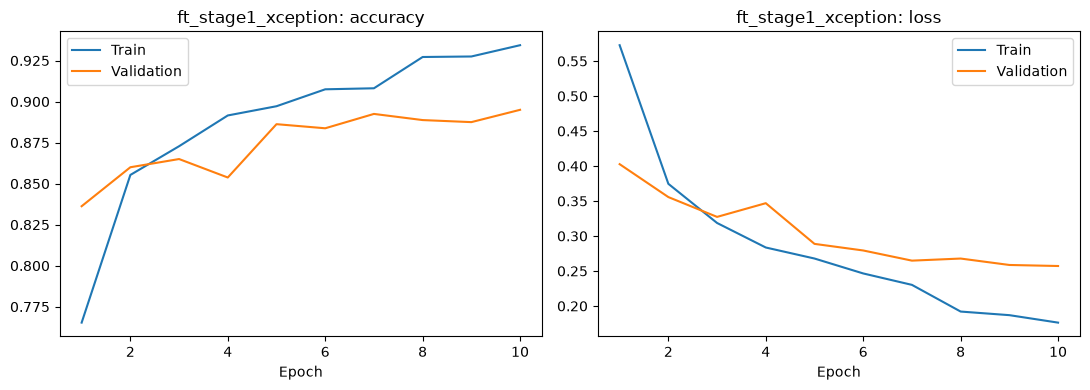

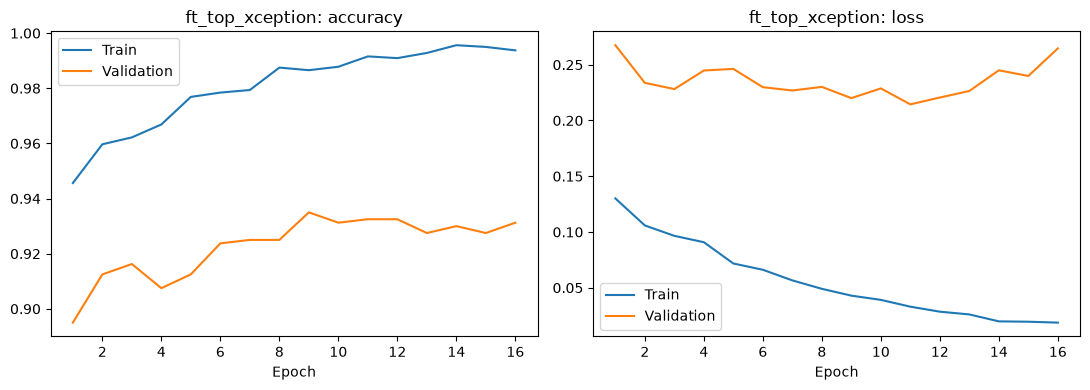

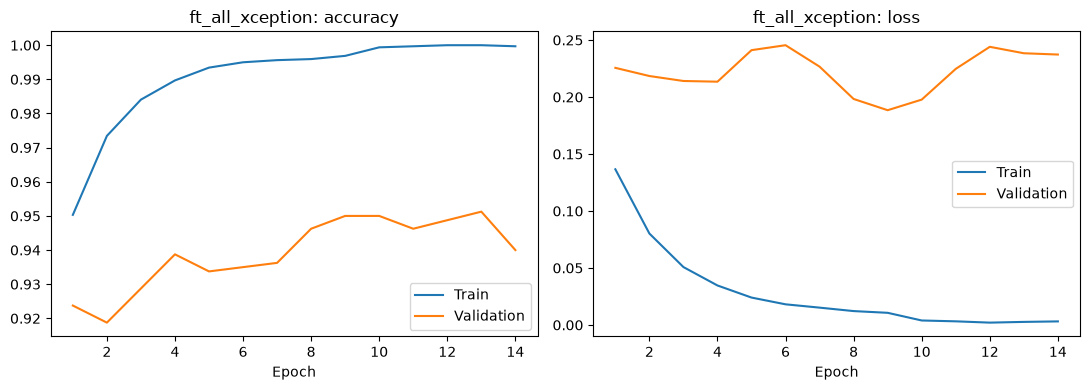

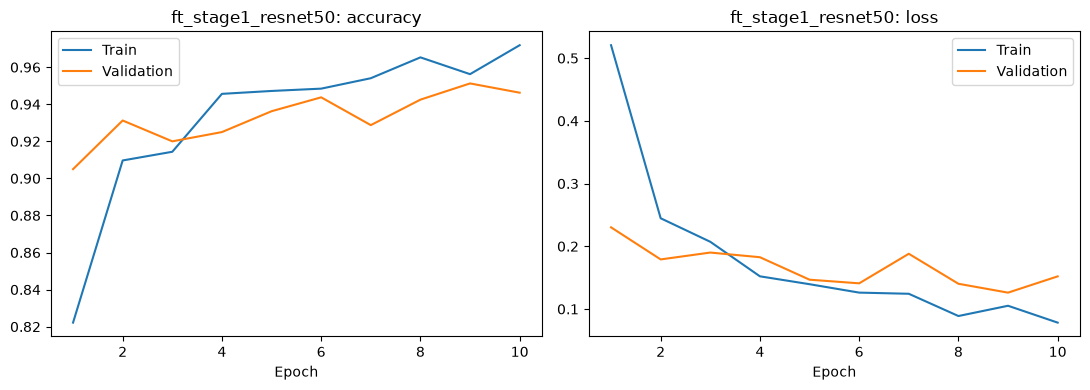

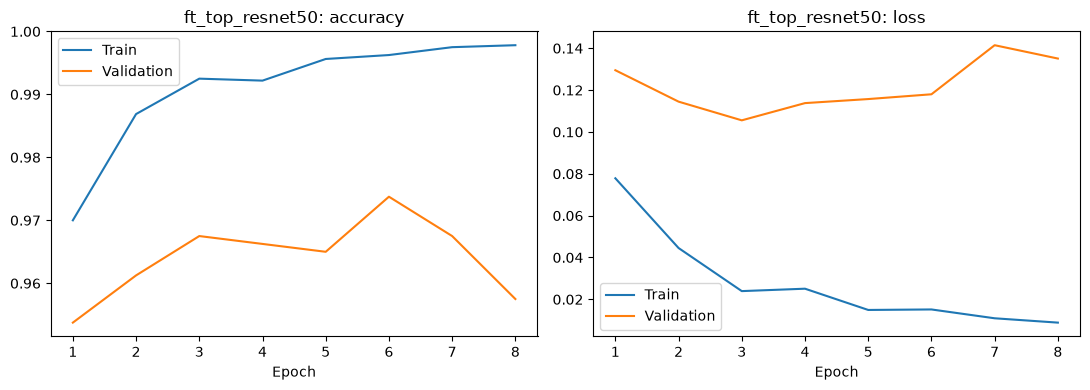

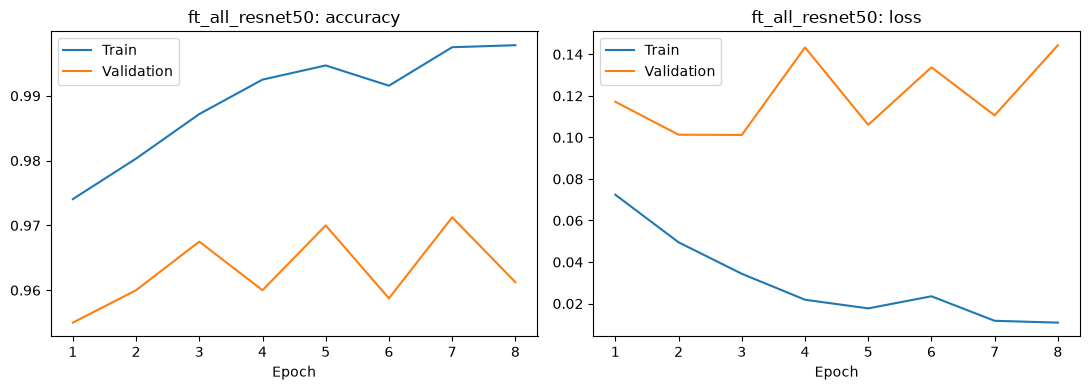

In [6]:
for run, name in RUNS:
    history = pd.read_csv(result_dir(run) / 'training_history.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(history['epoch'] + 1, history[metric], label='Train')
        ax.plot(history['epoch'] + 1, history['val_' + metric], label='Validation')
        ax.set(xlabel='Epoch', title=f'{run}: {metric}')
        ax.legend()
    plt.tight_layout()
    plt.savefig(result_dir(run) / 'accuracy_loss_curves.png', dpi=150)
    plt.show()

## Bước 5 – Đánh giá trên tập test

Nạp model tốt nhất của từng lần chạy rồi đánh giá trên test. Accuracy cho biết tỷ lệ dự đoán đúng; macro F1 là trung bình F1 của 4 lớp.

Confusion matrix có hàng là nhãn thật, cột là dự đoán. Xem thêm hai chiều nhầm smoke ↔ smokefire. Test chỉ dùng để báo cáo sau khi chọn model bằng validation.

===== ft_stage1_xception


,precision,recall,f1-score,support
fire,0.9535,0.6150,0.7477,200.0000
nofire,0.9698,0.9650,0.9674,200.0000
smoke,0.6466,0.9150,0.7578,200.0000
smokefire,0.5450,0.5150,0.5296,200.0000
accuracy,0.7525,0.7525,0.7525,0.7525
macro avg,0.7787,0.7525,0.7506,800.0000
weighted avg,0.7787,0.7525,0.7506,800.0000


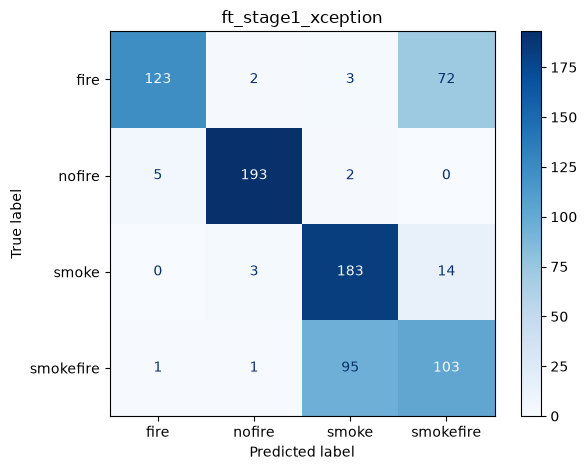

Accuracy: 75.25% | Macro F1: 0.7506
smokefire → smoke: 95 | smoke → smokefire: 14


===== ft_top_xception


,precision,recall,f1-score,support
fire,0.9695,0.6350,0.7674,200.0000
nofire,0.9701,0.9750,0.9726,200.0000
smoke,0.7137,0.8850,0.7902,200.0000
smokefire,0.5909,0.6500,0.6190,200.0000
accuracy,0.7862,0.7862,0.7862,0.7862
macro avg,0.8111,0.7862,0.7873,800.0000
weighted avg,0.8111,0.7862,0.7873,800.0000


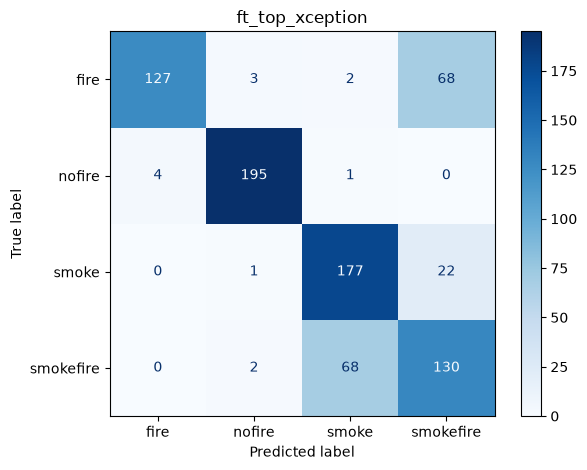

Accuracy: 78.62% | Macro F1: 0.7873
smokefire → smoke: 68 | smoke → smokefire: 22


===== ft_all_xception


,precision,recall,f1-score,support
fire,0.9750,0.5850,0.7312,200.0000
nofire,0.9849,0.9800,0.9825,200.0000
smoke,0.7137,0.9100,0.8000,200.0000
smokefire,0.5752,0.6500,0.6103,200.0000
accuracy,0.7812,0.7812,0.7812,0.7812
macro avg,0.8122,0.7812,0.7810,800.0000
weighted avg,0.8122,0.7812,0.7810,800.0000


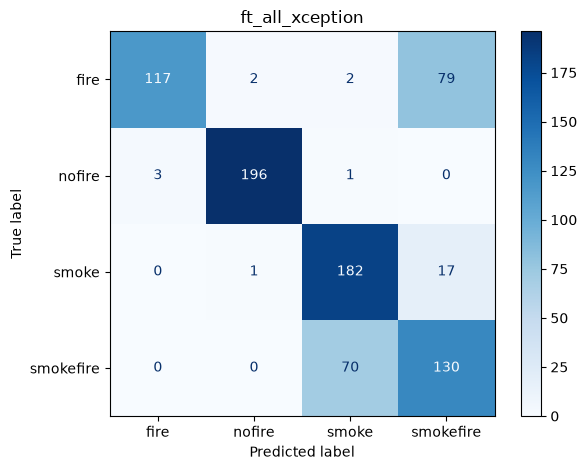

Accuracy: 78.12% | Macro F1: 0.7810
smokefire → smoke: 70 | smoke → smokefire: 17


===== ft_stage1_resnet50


,precision,recall,f1-score,support
fire,0.9530,0.7100,0.8138,200.0000
nofire,0.9798,0.9700,0.9749,200.0000
smoke,0.6573,0.9400,0.7737,200.0000
smokefire,0.6108,0.5100,0.5559,200.0000
accuracy,0.7825,0.7825,0.7825,0.7825
macro avg,0.8002,0.7825,0.7795,800.0000
weighted avg,0.8002,0.7825,0.7795,800.0000


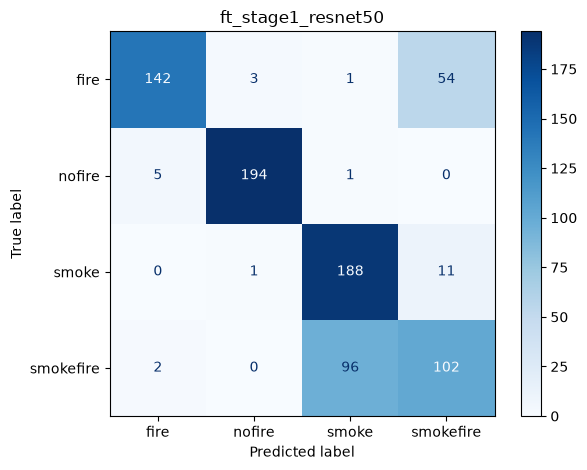

Accuracy: 78.25% | Macro F1: 0.7795
smokefire → smoke: 96 | smoke → smokefire: 11


===== ft_top_resnet50


,precision,recall,f1-score,support
fire,0.9930,0.7050,0.8246,200.0000
nofire,0.9900,0.9900,0.9900,200.0000
smoke,0.8000,0.8200,0.8099,200.0000
smokefire,0.6324,0.8000,0.7064,200.0000
accuracy,0.8288,0.8288,0.8288,0.8288
macro avg,0.8538,0.8287,0.8327,800.0000
weighted avg,0.8538,0.8288,0.8327,800.0000


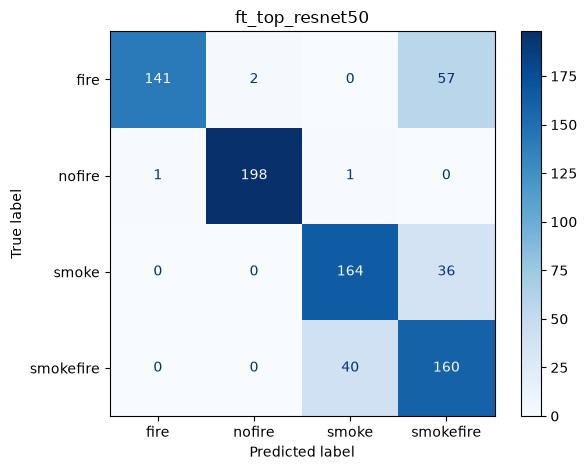

Accuracy: 82.88% | Macro F1: 0.8327
smokefire → smoke: 40 | smoke → smokefire: 36


===== ft_all_resnet50


,precision,recall,f1-score,support
fire,0.9859,0.7000,0.8187,200.0000
nofire,0.9899,0.9800,0.9849,200.0000
smoke,0.8268,0.7400,0.7810,200.0000
smokefire,0.6050,0.8500,0.7069,200.0000
accuracy,0.8175,0.8175,0.8175,0.8175
macro avg,0.8519,0.8175,0.8229,800.0000
weighted avg,0.8519,0.8175,0.8229,800.0000


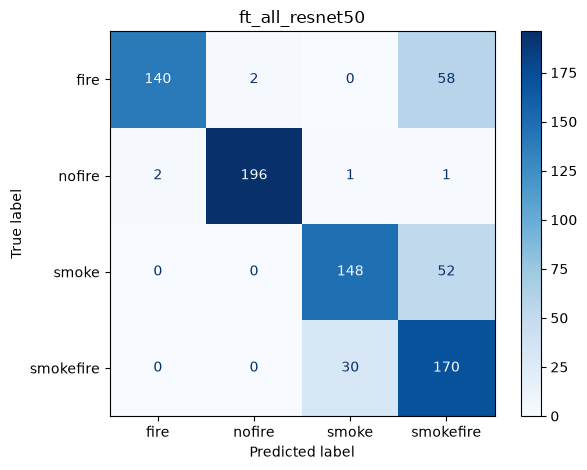

Accuracy: 81.75% | Macro F1: 0.8229
smokefire → smoke: 30 | smoke → smokefire: 52


In [7]:
results = {}
for run, name in RUNS:
    tf.keras.backend.clear_session()
    test_ds = make_dataset('test', BACKBONES[name][1])
    best_model = tf.keras.models.load_model(model_path(run))
    loss, accuracy = best_model.evaluate(test_ds, verbose=0)
    probabilities = best_model.predict(test_ds, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    assert np.isclose(accuracy, (y_true == y_pred).mean())
    report = classification_report(y_true, y_pred, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
    results[run] = {'loss': loss, 'accuracy': accuracy, 'probabilities': probabilities,
                    'report': report, 'matrix': matrix, 'parameter_count': best_model.count_params(),
                    'trainable_parameter_count': int(sum(np.prod(w.shape) for w in best_model.trainable_weights))}

    print('=====', run)
    display(pd.DataFrame(report).T.round(4))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(cmap='Blues')
    plt.title(run)
    plt.tight_layout()
    plt.savefig(result_dir(run) / 'confusion_matrix.png', dpi=150)
    plt.show()
    print(f'Accuracy: {accuracy:.2%} | Macro F1: {report["macro avg"]["f1-score"]:.4f}')
    print('smokefire → smoke:', matrix[3, 2], '| smoke → smokefire:', matrix[2, 3])

## Bước 6 – Lưu kết quả

Với mỗi lần chạy, lưu metrics, dự đoán từng ảnh, danh sách ảnh sai và confusion matrix tại `results/ft_<stage>_<backbone>_transfer_preprocessing/`. Bảng cuối so sánh sáu lần chạy trên tập test.

In [8]:
for run, name in RUNS:
    r = results[run]
    stage = run.split('_')[1]
    out = result_dir(run)
    history = pd.read_csv(out / 'training_history.csv')
    y_pred = r['probabilities'].argmax(axis=1)
    predictions = test_df[['filepath', 'processed_filepath', 'label', 'class_index']].copy()
    predictions['predicted_label'] = np.array(CLASS_NAMES)[y_pred]
    predictions['confidence'] = r['probabilities'].max(axis=1)
    predictions.to_csv(out / 'predictions.csv', index=False)
    predictions[y_true != y_pred].to_csv(out / 'misclassified.csv', index=False)
    pd.DataFrame(r['report']).T.to_csv(out / 'classification_report.csv', index_label='class')
    pd.DataFrame(r['matrix'], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        out / 'confusion_matrix.csv', index_label='true_label')

    metrics = {
        'test_accuracy': float(r['accuracy']), 'test_loss': float(r['loss']),
        'macro_f1': r['report']['macro avg']['f1-score'],
        'misclassified_count': int((y_true != y_pred).sum()),
        'parameter_count': r['parameter_count'],
        'trainable_parameter_count': r['trainable_parameter_count'],
        'best_epoch': int(history['val_loss'].argmin()) + 1,
        'best_val_loss': float(history['val_loss'].min()),
        'class_names': CLASS_NAMES, 'image_size': list(IMAGE_SIZE), 'seed': SEED,
        'preprocessing': {'source': 'processed_filepath', 'manifest': 'data/split.csv',
            'normalization': f'keras.applications.{name}.preprocess_input', 'augmentation': 'horizontal_flip'},
        'training_config': {'backbone': name, 'stage': stage,
            **STAGES[stage], 'head': 'Dense 256 ReLU - Dropout 0.5 - Dense 4',
            'optimizer': 'Adam', 'batch_size': BATCH_SIZE, 'batchnorm': 'frozen',
            'mixed_precision': True},
        'tensorflow_version': tf.__version__,
    }
    (out / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    model_path(run).with_suffix('.labels.json').write_text(json.dumps(CLASS_NAMES), encoding='utf-8')

pd.DataFrame({run: {'test_accuracy': r['accuracy'], 'macro_f1': r['report']['macro avg']['f1-score'],
                    'trainable_params': r['trainable_parameter_count']}
              for run, r in results.items()}).T.round(4)

,test_accuracy,macro_f1,trainable_params
ft_stage1_xception,0.7525,0.7506,525572.0
ft_top_xception,0.7862,0.7873,7301236.0
ft_all_xception,0.7812,0.7810,21277996.0
ft_stage1_resnet50,0.7825,0.7795,525572.0
ft_top_resnet50,0.8288,0.8327,15479044.0
ft_all_resnet50,0.8175,0.8229,24007044.0
